# How to Use:


1.   Adjust variables where specified, including columns, conditionals, geography/geography type, and export type.
2.   Run...
3.   Check environment folder for the export, or use the python table for futher analysis







In [ ]:
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import geopandas as gpd

In [ ]:
exportType = 'none'
# 'xlsx' or 'excel', 'parquet', 'none', 'both'

# OR IMPORT existing parquet:
# mdf = pd.read_parquet('output.parquet (3).gzip')

baseData = "https://api.census.gov/data/2022/acs/acs5/pums"
includeColumnLabel = False
columns = ["POWSP","RAC1P","AGEP","SEX","HINCP", "R18", "COW","WKHP","JWMNP","VEH","JWAP","JWDP", "WAGP"]

conditionals = {"ESR": 1, "SCHL": "16:99", "JWTRNS":"2:99"}

geographyType = "division" # state, division, region
geography = ['*']

# STATE CODE
#  1 Alabama/AL          2 Alaska/AK           4 Arizona/AZ
#  5 Arkansas/AR         6 California/CA       8 Colorado/CO
#  9 Connecticut/CT     10 Delaware/DE        11 District of Columbia/DC
# 12 Florida/FL         13 Georgia/GA         15 Hawaii/HI
# 16 Idaho/ID           17 Illinois/IL        18 Indiana/IN
# 19 Iowa/IA            20 Kansas/KS          21 Kentucky/KY
# 22 Louisiana/LA       23 Maine/ME           24 Maryland/MD
# 25 Massachusetts/MA   26 Michigan/MI        27 Minnesota/MN
# 28 Mississippi/MS     29 Missouri/MO        30 Montana/MT
# 31 Nebraska/NE        32 Nevada/NV          33 New Hampshire/NH
# 34 New Jersey/NJ      35 New Mexico/NM      36 New York/NY
# 37 North Carolina/NC  38 North Dakota/ND    39 Ohio/OH
# 40 Oklahoma/OK        41 Oregon/OR          42 Pennsylvania/PA
# 44 Rhode Island/RI    45 South Carolina/SC  46 South Dakota/SD
# 47 Tennessee/TN       48 Texas/TX           49 Utah/UT
# 50 Vermont/VT         51 Virginia/VA        53 Washington/WA
# 54 West Virginia/WV   55 Wisconsin/WI       56 Wyoming/WY
# 72 Puerto Rico/PR
# '*' All (will break without many conditionals)

# DIVISION CODE
# 0 Puerto Rico
# 1 New England (Northeast region)
# 2 Middle Atlantic (Northeast region)
# 3 East North Central (Midwest region)
# 4 West North Central (Midwest region)
# 5 South Atlantic (South region)
# 6 East South Central (South region)
# 7 West South Central (South Region)
# 8 Mountain (West region)
# 9 Pacific (West region)

# REGION CODE
# 1 Northeast
# 2 Midwest
# 3 South
# 4 West
# 9 Puerto Rico

# SEE MAP FOR REFERENCE ON REGION, DIVISION, & STATE
# https://www2.census.gov/geo/pdfs/maps-data/maps/reference/us_regdiv.pdf

In [ ]:
# Add conditionals to columns
originalColumns = columns.copy()

columns.extend(list(conditionals.keys()))
columns.append(geographyType.upper())

# Collect Variable Data
columnsData = []
for variable in columns:
  varBase = pd.read_json(baseData + "/variables/" + variable + ".json")
  if 'predicateType' not in varBase:
    varBase['predicateType'] = 'int'
  columnsData.append(dict(
      var=varBase.name.values[0].upper(),
      label=varBase.label.values[0],
      ptype=varBase.predicateType.values[0],
      values=pd.Series(data=varBase["values"].values[0]),
      range= len(varBase.values) > 1
      ))

# remap {"string": str, "int": int} and create dictionary
dataTypeDict = {}
for column in columnsData:
  column['ptype'] = column['ptype'].replace("string", "str")
  dataTypeDict[column['var']] = column['ptype']

# Create the conditional based on given dictionary
conditionalsString = "" #leave blank
for key, value in conditionals.items():
  conditionalsString = conditionalsString + "&" + key + "=" + str(value)

# API string constructor
fullString = baseData + "?get=" + ','.join(originalColumns) + conditionalsString  + "&descriptive=" + str(includeColumnLabel) + "&outputFormat=csv" + "&for=" + geographyType + ":" + ",".join(f"{num}" for num in geography)  + "&key=" + "!!!API KEY GOES HERE!!!" #Census provided API Key
print(fullString)
df = pd.read_csv(fullString, dtype=dataTypeDict)
df

# GETTING AN ERROR? You probably are missing the API KEY in your environment variables, reach out to me if this is the case and I can provide

https://api.census.gov/data/2022/acs/acs5/pums?get=POWSP,RAC1P,AGEP,SEX,HINCP,R18,COW,WKHP,JWMNP,VEH,JWAP,JWDP,WAGP&ESR=1&SCHL=16:99&JWTRNS=2:99&descriptive=False&outputFormat=csv&for=division:*&key=7e46a456a00762a49cc734f4983620bedb6894e9


,POWSP,RAC1P,AGEP,SEX,HINCP,R18,COW,WKHP,JWMNP,VEH,JWAP,JWDP,WAGP,ESR,SCHL,JWTRNS,division
0,034,1,51,1,-60000,-1,1,40,0,-1,0,0,38000,1,20,11,2
1,048,2,21,2,-60000,-1,3,10,5,-1,203,121,3200,1,16,10,7
2,036,1,21,1,-60000,-1,1,2,2,-1,283,150,1000,1,20,10,2
3,005,1,19,2,-60000,-1,1,15,10,-1,84,43,5600,1,19,10,7
4,006,1,21,1,-60000,-1,4,20,10,-1,180,109,7700,1,16,10,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1323430,038,9,39,2,170000,1,1,40,0,4,0,0,50000,1,21,11,4
1323431,025,1,19,2,10400,0,2,15,5,0,101,61,2900,1,16,10,1
1323432,025,8,21,2,10400,0,2,20,10,0,178,108,4000,1,16,10,1
1323433,025,1,20,2,10400,0,2,20,4,0,107,67,3500,1,19,10,1


In [ ]:
# Do some index magic...
df.columns = df.columns.str.upper()

for column in columnsData:
  reset_index = column['values'].reset_index()
  if column['ptype'] == "int":
    reset_index["index"] = pd.to_numeric(reset_index["index"], errors="ignore")
  reset_index.sort_values(by="index", inplace=True)
  varRef = reset_index.iloc[:, -1]
  varRef.index =reset_index["index"]

  column['values'] = varRef

/tmp/ipykernel_5142/2440314058.py:7: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  reset_index["index"] = pd.to_numeric(reset_index["index"], errors="ignore")
/tmp/ipykernel_5142/2440314058.py:7: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  reset_index["index"] = pd.to_numeric(reset_index["index"], errors="ignore")
/tmp/ipykernel_5142/2440314058.py:7: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  reset_index["index"] = pd.to_numeric(reset_index["index"], errors="ignore")
/tmp/ipykernel_5142/2440314058.py:7: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exce

In [ ]:
# Map variables to columns
mdf = df.copy()
for column in columnsData:
  if not column['range']:
    mdf[column['var']] = mdf[column['var']].map(column['values'])

mdf

,POWSP,RAC1P,AGEP,SEX,HINCP,R18,COW,WKHP,JWMNP,VEH,JWAP,JWDP,WAGP,ESR,SCHL,JWTRNS,DIVISION
0,New Jersey/NJ,White alone,51,Male,-60000,N/A (GQ/vacant),Employee of a private for-profit company or bu...,40,0,N/A (GQ/vacant),N/A (not a worker; worker who worked at home),N/A (not a worker; worker who worked at home),38000,"Civilian employed, at work",Associate's degree,Worked from home,Middle Atlantic (Northeast region)
1,Texas/TX,Black or African American alone,21,Female,-60000,N/A (GQ/vacant),"Local government employee (city, county, etc.)",10,5,N/A (GQ/vacant),5:05 p.m. to 5:09 p.m.,5:00 p.m. to 5:09 p.m.,3200,"Civilian employed, at work",Regular high school diploma,Walked,West South Central (South Region)
2,New York/NY,White alone,21,Male,-60000,N/A (GQ/vacant),Employee of a private for-profit company or bu...,2,2,N/A (GQ/vacant),11:45 p.m. to 11:49 p.m.,11:30 p.m. to 11:59 p.m.,1000,"Civilian employed, at work",Associate's degree,Walked,Middle Atlantic (Northeast region)
3,Arkansas/AR,White alone,19,Female,-60000,N/A (GQ/vacant),Employee of a private for-profit company or bu...,15,10,N/A (GQ/vacant),7:10 a.m. to 7:14 a.m.,7:00 a.m. to 7:04 a.m.,5600,"Civilian employed, at work","1 or more years of college credit, no degree",Walked,West South Central (South Region)
4,California/CA,White alone,21,Male,-60000,N/A (GQ/vacant),State government employee,20,10,N/A (GQ/vacant),3:10 p.m. to 3:14 p.m.,3:00 p.m. to 3:09 p.m.,7700,"Civilian employed, at work",Regular high school diploma,Walked,Pacific (West region)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1323430,North Dakota/ND,Two or More Races,39,Female,170000,1 or more persons under 18 in household,Employee of a private for-profit company or bu...,40,0,4 Vehicles,N/A (not a worker; worker who worked at home),N/A (not a worker; worker who worked at home),50000,"Civilian employed, at work",Bachelor's degree,Worked from home,West North Central (Midwest region)
1323431,Massachusetts/MA,White alone,19,Female,10400,No person under 18 in household,"Employee of a private not-for-profit, tax-exem...",15,5,No vehicles,8:35 a.m. to 8:39 a.m.,8:30 a.m. to 8:34 a.m.,2900,"Civilian employed, at work",Regular high school diploma,Walked,New England (Northeast region)
1323432,Massachusetts/MA,Some Other Race alone,21,Female,10400,No person under 18 in household,"Employee of a private not-for-profit, tax-exem...",20,10,No vehicles,3:00 p.m. to 3:04 p.m.,2:50 p.m. to 2:59 p.m.,4000,"Civilian employed, at work",Regular high school diploma,Walked,New England (Northeast region)
1323433,Massachusetts/MA,White alone,20,Female,10400,No person under 18 in household,"Employee of a private not-for-profit, tax-exem...",20,4,No vehicles,9:05 a.m. to 9:09 a.m.,9:00 a.m. to 9:04 a.m.,3500,"Civilian employed, at work","1 or more years of college credit, no degree",Walked,New England (Northeast region)


In [ ]:
# Create Label Guide
labelGuide = pd.DataFrame(columns=['column', 'label'])

for column in columnsData:
  labelGuide.loc[len(labelGuide)] = {'column': column['var'], 'label': column['label']}
labelGuide

def giveDef(code):
  return labelGuide.loc[labelGuide['column'] == code]['label'].values[0]


for record, items in labelGuide.values:
  print(record + ": " + items)

POWSP: Place of work - State or foreign country recode
RAC1P: Recoded detailed race code (Note: due to space restrictions, some labels may be truncated.)
AGEP: Age
SEX: Sex
HINCP: Household income (past 12 months, use ADJINC to adjust HINCP to constant dollars)
R18: Presence of persons under 18 years in household (unweighted)
COW: Class of worker
WKHP: Usual hours worked per week past 12 months
JWMNP: Travel time to work
VEH: Vehicles (1 ton or less) available
JWAP: Time of arrival at work - hour and minute
JWDP: Time of departure for work - hour and minute
WAGP: Wages or salary income past 12 months (use ADJINC to adjust WAGP to constant dollars)
ESR: Employment status recode
SCHL: Educational attainment
JWTRNS: Means of transportation to work
DIVISION: Division code


In [ ]:
if (exportType.lower() in ['xlsx', 'excel', 'both']):
  # RUN TO EXPORT TO EXCEL FILE
  with pd.ExcelWriter('output.xlsx') as writer:
      mdf.to_excel(writer, sheet_name="Primary Data")
      labelGuide.to_excel(writer, sheet_name="Label Guide")
      print("Excel Output Created")


# mdf.to_csv('output.csv', index=False)

In [ ]:
if (exportType.lower() in ['parquet', 'both']):
  # RUN TO EXPORT TO PARQUET FILE (For easy storage)
  mdf.to_parquet('output.parquet.gzip', compression='gzip')
  print("Parquet Output Created")

In [ ]:
# Space for python analysis (use dataframe 'mdf'):

display(mdf.describe)

display(mdf.corr(numeric_only=True).style.background_gradient())

<bound method NDFrame.describe of                     POWSP                            RAC1P  AGEP     SEX  \
0           New Jersey/NJ                      White alone    51    Male   
1                Texas/TX  Black or African American alone    21  Female   
2             New York/NY                      White alone    21    Male   
3             Arkansas/AR                      White alone    19  Female   
4           California/CA                      White alone    21    Male   
...                   ...                              ...   ...     ...   
1323430   North Dakota/ND                Two or More Races    39  Female   
1323431  Massachusetts/MA                      White alone    19  Female   
1323432  Massachusetts/MA            Some Other Race alone    21  Female   
1323433  Massachusetts/MA                      White alone    20  Female   
1323434     New Jersey/NJ                      Asian alone    26  Female   

          HINCP                                      R18  \
0        -60000                          N/A (GQ/vacant)   
1        -60000                          N/A (GQ/vacant)   
2        -60000                          N/A (GQ/vacant)   
3        -60000                          N/A (GQ/vacant)   
4        -60000                          N/A (GQ/vacant)   
...         ...                                      ...   
1323430  170000  1 or more persons under 18 in household   
1323431   10400          No person under 18 in household   
1323432   10400          No person under 18 in household   
1323433   10400          No person under 18 in household   
1323434   26000  1 or more persons under 18 in household   

                                                       COW  WKHP  JWMNP  \
0        Employee of a private for-profit company or bu...    40      0   
1           Local government employee (city, county, etc.)    10      5   
2        Employee of a private for-profit company or bu...     2      2   
3        Employee of a private for-profit company or bu...    15     10   
4                                State government employee    20     10   
...                                                    ...   ...    ...   
1323430  Employee of a private for-profit company or bu...    40      0   
1323431  Employee of a private not-for-profit, tax-exem...    15      5   
1323432  Employee of a private not-for-profit, tax-exem...    20     10   
1323433  Employee of a private not-for-profit, tax-exem...    20      4   
1323434  Employee of a private for-profit company or bu...    50      0   

                     VEH                                           JWAP  \
0        N/A (GQ/vacant)  N/A (not a worker; worker who worked at home)   
1        N/A (GQ/vacant)                         5:05 p.m. to 5:09 p.m.   
2        N/A (GQ/vacant)                       11:45 p.m. to 11:49 p.m.   
3        N/A (GQ/vacant)                         7:10 a.m. to 7:14 a.m.   
4        N/A (GQ/vacant)                         3:10 p.m. to 3:14 p.m.   
...                  ...                                            ...   
1323430       4 Vehicles  N/A (not a worker; worker who worked at home)   
1323431      No vehicles                         8:35 a.m. to 8:39 a.m.   
1323432      No vehicles                         3:00 p.m. to 3:04 p.m.   
1323433      No vehicles                         9:05 a.m. to 9:09 a.m.   
1323434        1 vehicle  N/A (not a worker; worker who worked at home)   

                                                  JWDP   WAGP  \
0        N/A (not a worker; worker who worked at home)  38000   
1                               5:00 p.m. to 5:09 p.m.   3200   
2                             11:30 p.m. to 11:59 p.m.   1000   
3                               7:00 a.m. to 7:04 a.m.   5600   
4                               3:00 p.m. to 3:09 p.m.   7700   
...                                                ...    ...   
1323430  N/A (not a worker; worker who worked at home)  50000   
1323431   

,AGEP,HINCP,WKHP,JWMNP,WAGP
AGEP,1.000000,0.159656,0.067728,-0.068586,0.124853
HINCP,0.159656,1.000000,0.229662,-0.020556,0.676838
WKHP,0.067728,0.229662,1.000000,0.022339,0.337578
JWMNP,-0.068586,-0.020556,0.022339,1.000000,0.008889
WAGP,0.124853,0.676838,0.337578,0.008889,1.000000


# **Analysis Start**
Question:

Can we predict an individual's primary mode of transportation based on demographic, region, or other data?

Final Analysis Charts Located in PowerBI below. Used to ensure consistent and effective styling.
https://iowastate-my.sharepoint.com/:u:/g/personal/noamhaz_iastate_edu/IQCDQydB3Wk2QavXO0Z9_pGSAXwx5nmlfPobFqU_zYDzBl0?e=MRIsJB

In [ ]:
# Noam:

filtering = [item for sublist in list(mdf[['POWSP']].value_counts()[mdf[['POWSP']].value_counts() > 1000].index.values) for item in sublist]
mdf = mdf[mdf['POWSP'].isin(filtering)]
mdf[['POWSP']].value_counts()

selectTop = 5 # for selecting only the top states based on population

# Since this geography is set to west coast, removing all states, but ones with 1000 or more people working in

popStates = [item for sublist in list(mdf[['POWSP']].value_counts()[mdf[['POWSP']].value_counts() >= mdf[['POWSP']].value_counts().iloc[selectTop - 1]].index.values) for item in sublist]

tdf = mdf[mdf['POWSP'].isin(popStates)]
tdf[['POWSP']].value_counts()

dis = mdf[mdf['JWTRNS'].isin([item for sublist in list(mdf[['JWTRNS']].value_counts()[mdf[['JWTRNS']].value_counts() >= mdf[['JWTRNS']].value_counts().iloc[5 - 1]].index.values) for item in sublist])]

tdis = dis[dis['POWSP'].isin([item for sublist in list(dis[['POWSP']].value_counts()[dis[['POWSP']].value_counts() >= dis[['POWSP']].value_counts().iloc[5 - 1]].index.values) for item in sublist])]


# mdf is the primary df
# tdf is mdf with only top 5 state data included
# dis is mdf with only the top 5 means of transportation to work
# tdis is dis with only the top 5 state data included

/tmp/ipykernel_5142/2570364233.py:6: UserWarning: The palette list has more values (8) than needed (5), which may not be intended.
  c1 = sns.catplot(data=tdf, x="JWMNP", y="POWSP", hue="POWSP", kind="violin", height=10, split=True, cut=0, palette=sns.color_palette(pal, len(pal)), linewidth=.5, edgecolor="#FFFFFF")


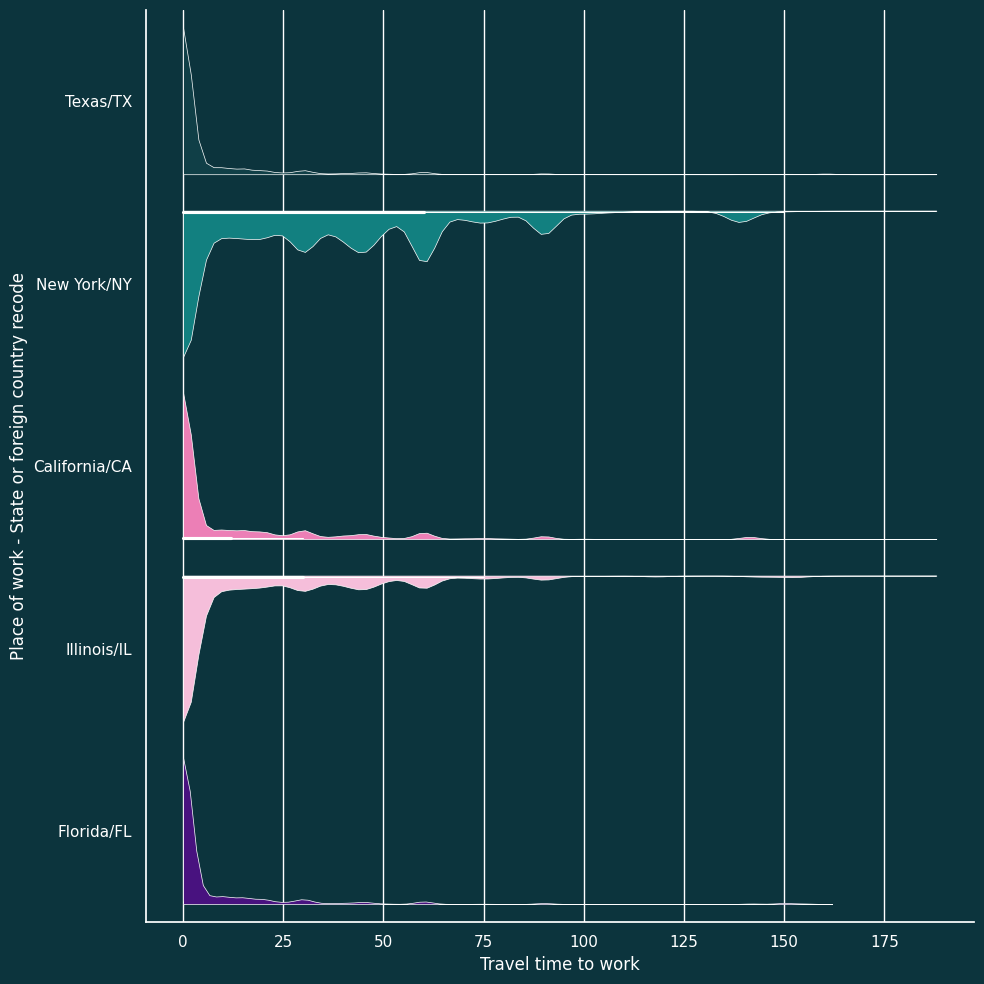

In [ ]:
# td = sns.FacetGrid(tdf, col="POWSP", height=20)
# td.map_dataframe(sns.catplot, y="JWTRNS", x="JWMNP", kind="violin")

pal = ['#074650', '#009292', '#fe6db6', '#feb5da', '#480091', '#b66dff', '#b5dafe', '#6db6ff']
sns.set(rc={'axes.facecolor':'#0c343d', 'figure.facecolor':'#0c343d', "ytick.color": "#FFFFFF", "xtick.color": "#FFFFFF", "axes.labelcolor": "#FFFFFF", "axes.edgecolor": "#FFFFFF", "text.color": "#FFFFFF"})
c1 = sns.catplot(data=tdf, x="JWMNP", y="POWSP", hue="POWSP", kind="violin", height=10, split=True, cut=0, palette=sns.color_palette(pal, len(pal)), linewidth=.5, edgecolor="#FFFFFF")
c1.set_xlabels(giveDef("JWMNP"))
c1.set_ylabels(giveDef("POWSP"))

/tmp/ipykernel_5142/381136123.py:2: UserWarning: 
The palette list has fewer values (8) than needed (11) and will cycle, which may produce an uninterpretable plot.
  c2 = sns.catplot(data=mdf, x="JWMNP", y="JWTRNS", hue="JWTRNS", kind="violin", height=12, split=True, cut=0, palette=sns.color_palette(pal, len(pal)), linewidth=.5, edgecolor="#FFFFFF")


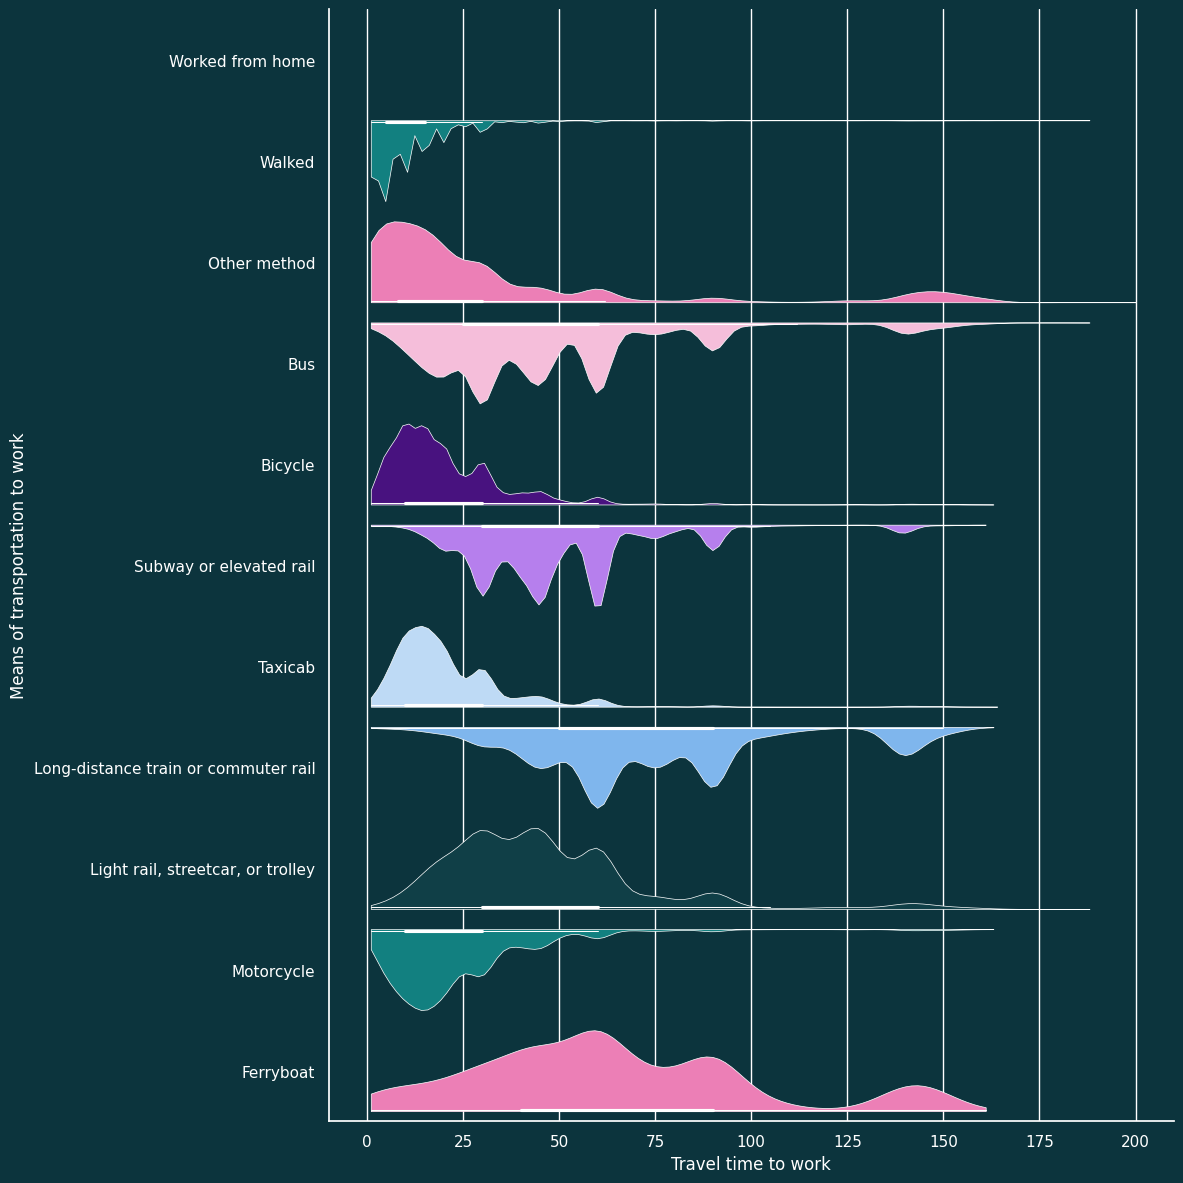

In [ ]:
sns.set(rc={'axes.facecolor':'#0c343d', 'figure.facecolor':'#0c343d', "ytick.color": "#FFFFFF", "xtick.color": "#FFFFFF", "axes.labelcolor": "#FFFFFF", "axes.edgecolor": "#FFFFFF", "text.color": "#FFFFFF",})
c2 = sns.catplot(data=mdf, x="JWMNP", y="JWTRNS", hue="JWTRNS", kind="violin", height=12, split=True, cut=0, palette=sns.color_palette(pal, len(pal)), linewidth=.5, edgecolor="#FFFFFF")
c2.set_xlabels(giveDef("JWMNP"))
c2.set_ylabels(giveDef("JWTRNS"))

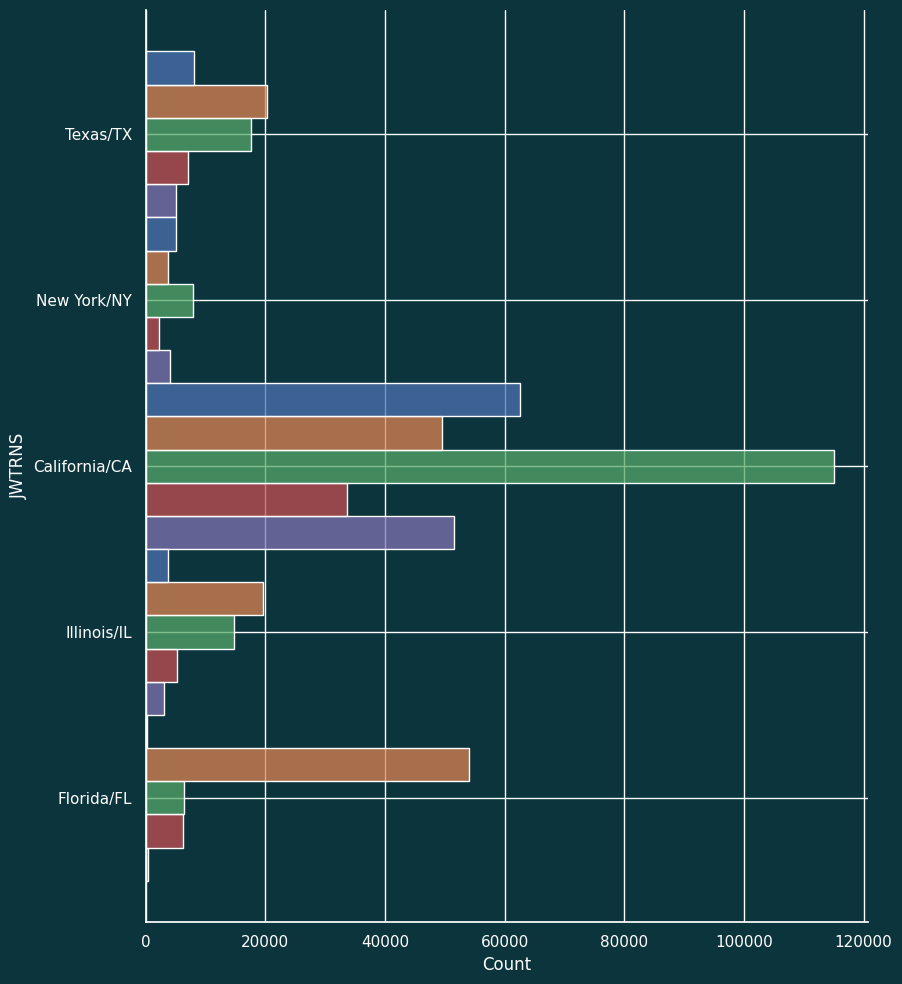

In [ ]:
ax = sns.displot(tdis, y="JWTRNS", hue="POWSP", legend=False, height=10, multiple="dodge", hue_order = tdis["POWSP"].unique())
# plt.tight_layout()
ax.set_yticklabels(tdis["POWSP"].unique())
plt.show()

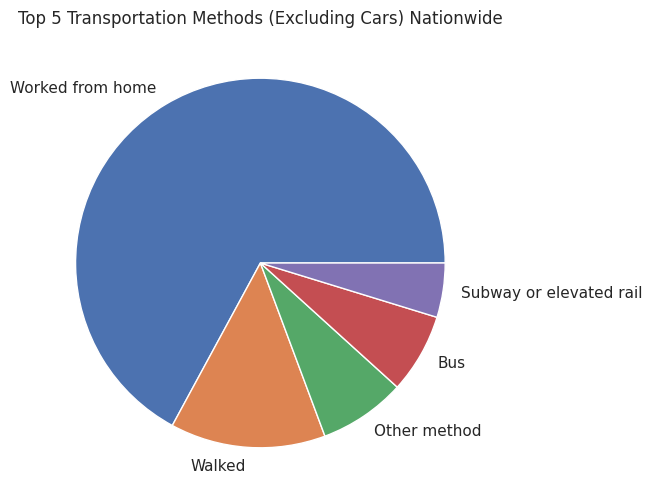

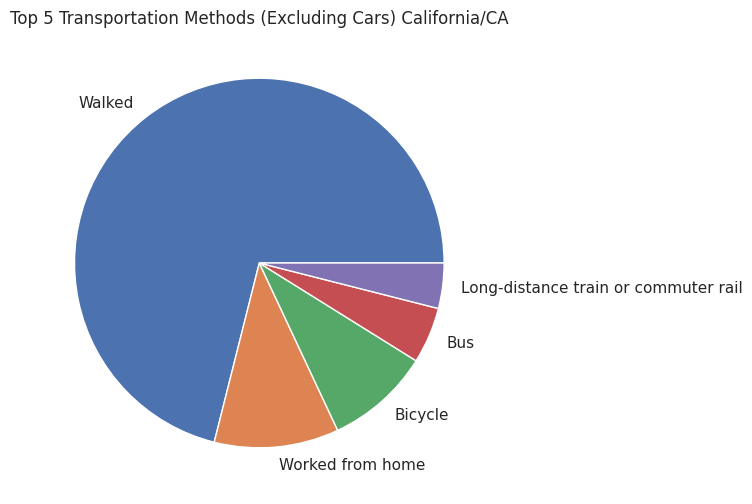

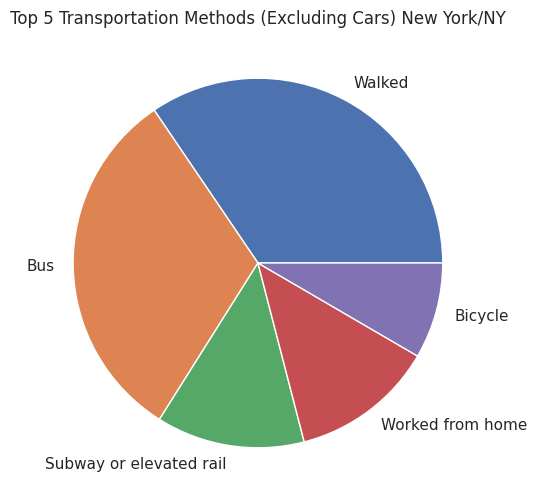

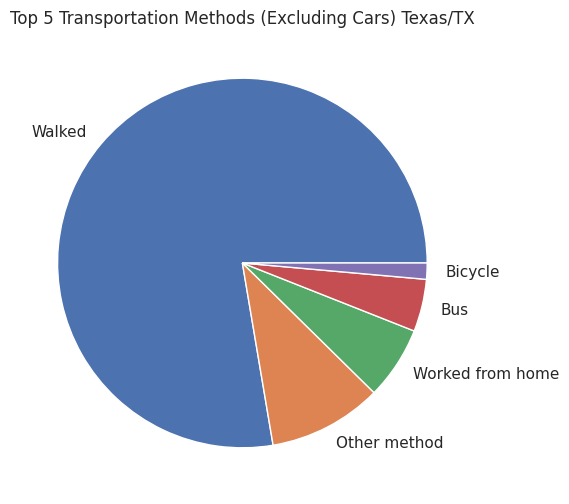

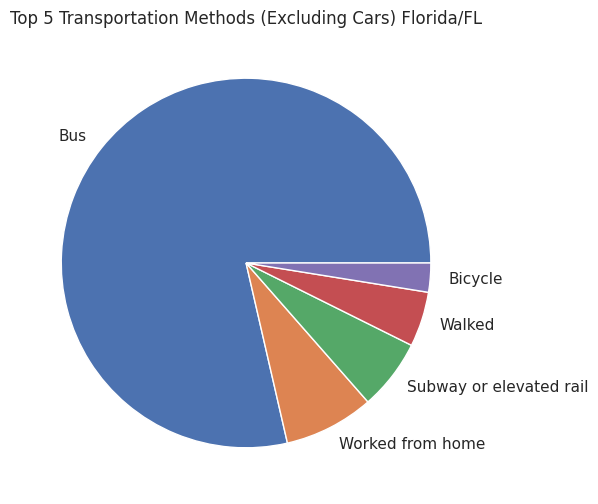

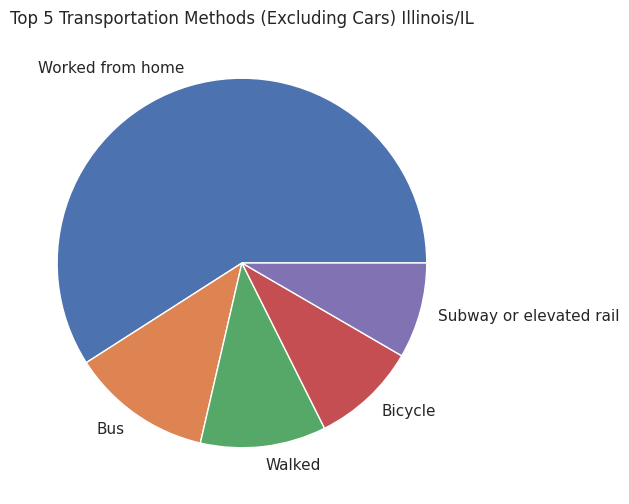

In [ ]:
sns.set_style("whitegrid")
plt.figure(figsize=(6,6))
plt.pie(dis['JWTRNS'].value_counts(), labels=dis['JWTRNS'].unique())
plt.title('Top 5 Transportation Methods (Excluding Cars) Nationwide')
plt.show()

for POWSP in popStates:
  sns.set_style("whitegrid")
  plt.figure(figsize=(6,6))
  plt.pie(mdf.loc[mdf['POWSP'] == POWSP, ['JWTRNS']].value_counts().head(5), labels= mdf.loc[mdf['POWSP'] == POWSP, 'JWTRNS'].unique()[0:5])
  plt.title('Top 5 Transportation Methods (Excluding Cars) ' + POWSP)


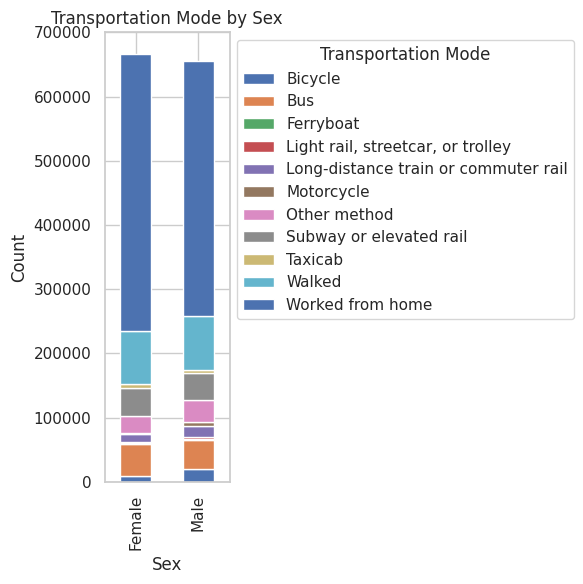

In [ ]:
pd.crosstab(mdf['SEX'], mdf['JWTRNS']).plot(
    kind='bar',
    stacked=True,
    figsize=(6,6)
)
plt.title("Transportation Mode by Sex")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.legend(title="Transportation Mode", bbox_to_anchor=(1,1))
plt.tight_layout()
plt.show()


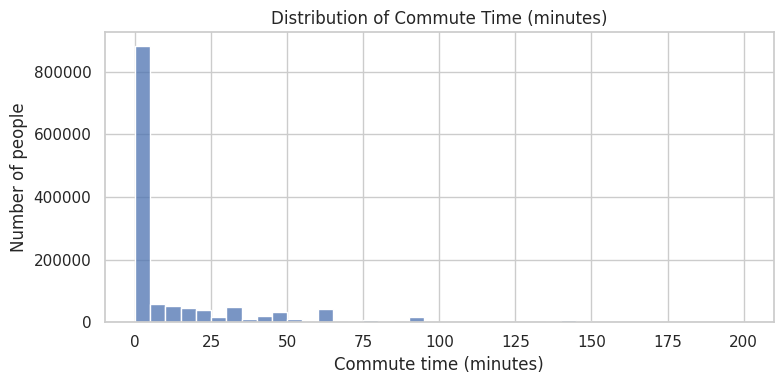

In [ ]:
# Shiva

# Distribution of Commute Time

plt.figure(figsize=(8, 4))
sns.histplot(data=mdf, x='JWMNP', bins=40)
plt.title('Distribution of Commute Time (minutes)')
plt.xlabel('Commute time (minutes)')
plt.ylabel('Number of people')
plt.tight_layout()
plt.show()

Most people have a short commutes, with the majority travel between 10 and 30 minutes, while long commutes are much less common.

In [ ]:
# Average commute time by mode of transportation

commute_by_mode = (
    mdf.groupby('JWTRNS')['JWMNP']
       .mean()
       .sort_values()
)

commute_by_mode

,JWMNP
JWTRNS,
Worked from home,0.000000
Walked,11.167080
Bicycle,20.805447
Taxicab,21.717748
Motorcycle,23.438976
Other method,32.045776
"Light rail, streetcar, or trolley",46.195394
Bus,47.382956
Subway or elevated rail,49.431436


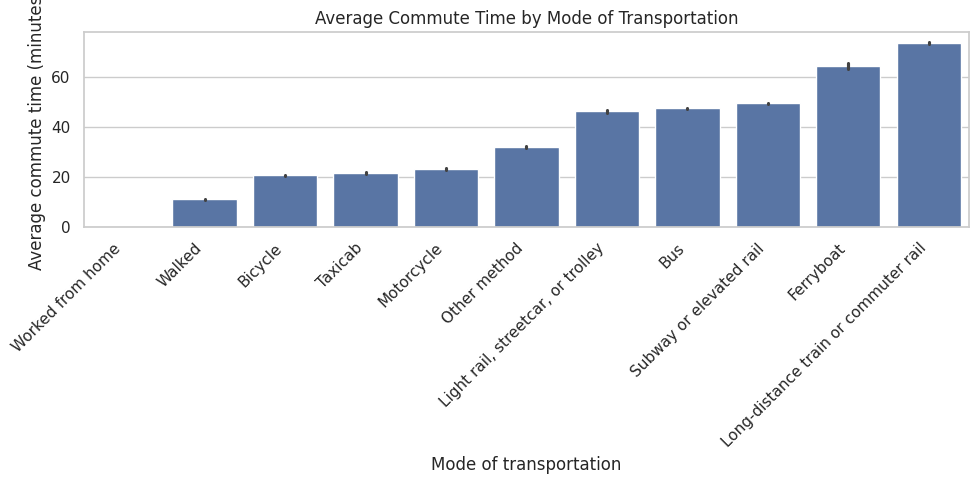

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=mdf,
    x='JWTRNS',
    y='JWMNP',
    estimator='mean',
    order=commute_by_mode.index
)
plt.xticks(rotation=45, ha='right')
plt.title('Average Commute Time by Mode of Transportation')
plt.xlabel('Mode of transportation')
plt.ylabel('Average commute time (minutes)')
plt.tight_layout()
plt.show()

In [ ]:
# POWSP   - Place of work (state or foreign country)
# RAC1P   - Recoded detailed race
# AGEP    - Age (in years)
# SEX     - Sex
# HINCP   - Household income (past 12 months)
# R18     - Presence of persons under 18 in household
# COW     - Class of worker
# WKHP    - Usual hours worked per week (past 12 months)
# JWMNP   - Travel time to work (minutes)
# VEH     - Vehicles available in household
# JWAP    - Time of arrival at work
# JWDP    - Time of departure for work
# WAGP    - Wage or salary income (past 12 months)
# ESR     - Employment status recode
# SCHL    - Educational attainment
# JWTRNS  - Means of transportation to work
# DIVISION- Census geographic division


In [ ]:
dft= mdf.copy()

veh_map = {
    "No vehicles": 0,
    "1 vehicle": 1,
    "2 vehicles": 2,
    "3 vehicles": 3,
    "4 vehicles": 4,
    "5 vehicles": 5,
    "6 or more vehicles": 6,
}
dft['VEH'] = dft['VEH'].map(veh_map)

In [ ]:
#dft['JWTRNS'].value_counts()
#dft = dft[dft['JWTRNS']!='Worked from home']
dft['POWSP'].value_counts()

,count
POWSP,
California/CA,175839
New York/NY,167122
Texas/TX,82575
Florida/FL,68013
Illinois/IL,61725
Pennsylvania/PA,54287
Massachusetts/MA,50028
Washington/WA,41679
New Jersey/NJ,41627


In [ ]:
numeric_features = [
    "AGEP",
    "WKHP",
    "JWMNP",
    "HINCP",
    "WAGP",
    "VEH",
]

categorical_features = [
    "SEX",
    "RAC1P",
    "COW",
    "SCHL",
    "DIVISION",
    "POWSP",
    "R18",
]

var_to_drop = [
    "JWAP", "JWDP", "JWTRNS", "ESR"
]

# POWSP   - Place of work (state or foreign country)
# RAC1P   - Recoded detailed race
# AGEP    - Age (in years)
# SEX     - Sex
# HINCP   - Household income (past 12 months)
# R18     - Presence of persons under 18 in household
# COW     - Class of worker
# WKHP    - Usual hours worked per week (past 12 months)
# JWMNP   - Travel time to work (minutes)
# VEH     - Vehicles available in household
# JWAP    - Time of arrival at work
# JWDP    - Time of departure for work
# WAGP    - Wage or salary income (past 12 months)
# ESR     - Employment status recode
# SCHL    - Educational attainment
# JWTRNS  - Means of transportation to work
# DIVISION- Census geographic division

In [ ]:
X = dft.drop(var_to_drop, axis=1)
y= dft['JWTRNS']

X_encoded = pd.get_dummies(X[categorical_features])
X_final = pd.concat([X[numeric_features], X_encoded], axis=1)
X_final

,AGEP,WKHP,JWMNP,HINCP,WAGP,VEH,SEX_Female,SEX_Male,RAC1P_Alaska Native alone,RAC1P_American Indian alone,...,POWSP_Utah/UT,POWSP_Vermont/VT,POWSP_Virginia/VA,POWSP_Washington/WA,POWSP_West Virginia/WV,POWSP_Wisconsin/WI,POWSP_Wyoming/WY,R18_1 or more persons under 18 in household,R18_N/A (GQ/vacant),R18_No person under 18 in household
0,51,40,0,-60000,38000,NaN,False,True,False,False,...,False,False,False,False,False,False,False,False,True,False
1,21,10,5,-60000,3200,NaN,True,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,21,2,2,-60000,1000,NaN,False,True,False,False,...,False,False,False,False,False,False,False,False,True,False
3,19,15,10,-60000,5600,NaN,True,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,21,20,10,-60000,7700,NaN,False,True,False,False,...,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1323430,39,40,0,170000,50000,NaN,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1323431,19,15,5,10400,2900,0.0,True,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1323432,21,20,10,10400,4000,0.0,True,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1323433,20,20,4,10400,3500,0.0,True,False,False,False,...,False,False,False,False,False,False,False,False,False,True


In [ ]:
# Basic RF model, no hyperparameters, but "feature engineered" in that useless columns are removed
from sklearn.model_selection import train_test_split

trainX, testX, trainY, testY = train_test_split(X_final,y,test_size = 0.2, stratify = y,random_state = 67)

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(trainX, trainY)



RandomForestClassifier(random_state=42)

In [ ]:
y_pred = rf.predict(testX)
print(rf.score(testX, testY))

from sklearn.model_selection import cross_val_score
scores = cross_val_score(rf, trainX, trainY, cv=3)
print("→ mean CV acc:", scores.mean())

#0.8451113957240061

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(testY, y_pred))

In [ ]:
features = pd.DataFrame(rf.feature_importances_, index = trainX.columns, columns = ['importance'])
features = features.sort_values('importance', ascending = False)
features

In [ ]:
y_pred = rf.predict(testX)
rf.score(testX, testY)

scores = cross_val_score(rf, trainX, trainY, cv=5)
print("→ mean CV acc:", scores.mean())

In [ ]:
#print("Model accuracy:", rf.score(testX, testY))

majority_class = testY.value_counts().
majority_class
baseline_acc = (testY == majority_class).mean()
print("Baseline (majority class) accuracy:", baseline_acc)

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

gb = HistGradientBoostingClassifier(random_state=42)#early_stopping=True)
gb.fit(trainX, trainY)

print("GB test accuracy:", gb.score(testX, testY))

In [ ]:
hgb = HistGradientBoostingClassifier(
    learning_rate=0.1,
    max_iter=120,
    max_depth=8,
    min_samples_leaf=10,
    l2_regularization=0.5,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42
)

hgb.fit(trainX, trainY)
#print("HGB test accuracy:", hgb.score(testX, testY))
#scores = cross_val_score(hgb, trainX, trainY, cv=5)
#print("→ mean CV acc:", scores.mean())


In [ ]:
features = pd.DataFrame(hgb.feature_importances_, index = trainX.columns, columns = ['importance'])
features = features.sort_values('importance', ascending = False)
features

In [ ]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(hgb, trainX, trainY, cv=3)
print("→ mean CV acc:", scores.mean())
# 0.8476644111724414

In [ ]:
#confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

labels_shortened = ['Bike', 'Bus', 'Ferry', 'Light Rail', 'Train', 'Motorcycle', 'Other', 'Subway', 'Taxi', 'Walked', 'Home']

y_pred = hgb.predict(testX)
fix, ax = plt.subplots(figsize=(10,10))
disp = ConfusionMatrixDisplay.from_predictions(testY, y_pred, display_labels = labels_shortened, ax=ax, cmap = 'Blues', normalize = "true")

from sklearn.metrics import classification_report
print(classification_report(testY, y_pred))


test

In [ ]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV

MAX_TUNE_SAMPLES = 10000

if len(trainX) > MAX_TUNE_SAMPLES:
    smallX = trainX.sample(MAX_TUNE_SAMPLES, random_state=42)
    smallY = trainY.loc[smallX.index]
else:
    smallX = trainX
    smallY = trainY

hgb_base = HistGradientBoostingClassifier(
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42
)

param_dist_hgb = {
    "learning_rate":     [0.05, 0.1],
    "max_iter":          [80, 120],
    "max_depth":         [8, 10, 12],
    "min_samples_leaf":  [10, 20],
    "l2_regularization": [0.0, 0.1, 0.5],
}


hgb_search = RandomizedSearchCV(
    estimator=hgb_base,
    param_distributions=param_dist_hgb,
    n_iter=5,
    cv=3,
    n_jobs=-1,
    verbose=1,
    random_state=42
)

hgb_search.fit(smallX, smallY)

print("\nBest HGB params:")
print(hgb_search.best_params_)

print("\nBest mean CV accuracy:")
print(hgb_search.best_score_)



In [ ]:
#not useful

MAX_TUNE_SAMPLES = 50000

if len(trainX) > MAX_TUNE_SAMPLES:
    smallX = trainX.sample(MAX_TUNE_SAMPLES, random_state=42)
    smallY = trainY.loc[smallX.index]
else:
    smallX = trainX
    smallY = trainY

rf_base = RandomForestClassifier(
    n_estimators=200,
    n_jobs=-1,
    random_state=42,
    class_weight="balanced"
)

param_dist_rf = {
   "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 14, 18],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", "log2"],
}


rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist_rf,
    n_iter=10,
    cv=3,
    n_jobs=-1,
    verbose=1,
    random_state=42,
)

rf_search.fit(smallX, smallY)

print("\nBest RF params:")
print(rf_search.best_params_)

print("\nBest mean CV accuracy:")
print(rf_search.best_score_)

